# 01 - Inspeção, Limpeza e Janelamento do Dataset Cilia et al. (2022)

> **Iniciação Científica (IC) em Engenharia de Computação**  
> **Tema:** Detecção / Triagem de Transtorno do Espectro Autista (TEA) via Eye-Tracking e Deep Learning  
> **Protocolo de Validação:** Leave-One-Subject-Out Cross-Validation (LOSO-CV estrito)  
> **Fase:** Exploração prática, inspeção visual do pré-processamento e validação de tensores PyTorch.

---

## 🎯 Objetivos Deste Notebook
Com base na auditoria recém-executada (`relatorio_inspecao_cilia.md`), este notebook implementa de forma transparente e visual a primeira etapa prática de preparação dos dados brutos:

1. **Filtro Preliminar e Metadados:**
   - Carregar a ficha clínica (`Metadata_Participants.csv`) e mapear os rótulos de diagnóstico (`ASD` $\rightarrow 1$ e `TD` $\rightarrow 0$).
   - Descartar explicitamente os participantes **12** e **16** (identificados com ausência estrutural total de registros por falha/recusa na calibração).
   - Garantir a contagem estrita dos **57 participantes válidos** (27 ASD e 30 TD).
   - Carregar as séries temporais dos 25 arquivos de estímulo em `data/Eye-tracking Output/`, filtrando exclusivamente as colunas essenciais do olho direito e descartando linhas anônimas (`Unidentified`).

2. **Limpeza e Normalização Fisiológica:**
   - Ordenação temporal estrita por `RecordingTime [ms]`.
   - Conversão de coordenadas espúrias `(0, 0)` em `NaN` (códigos de hardware de perda de sinal do SMI RED).
   - Normalização espacial de $X$ e $Y$ para $[0.0, 1.0]$ baseada na resolução nativa de $1280 \times 1024$ pixels, com clipping defensivo.
   - Interpolação linear seletiva para piscares normais (*blinks* $\le 150$ ms / $\le 8$ amostras a 50 Hz).
   - Construção de máscara binária de validade do sinal (`valid_mask`).
   - Exibição de resumos quantitativos e inspeção gráfica (séries temporais e trajetórias 2D).

3. **Segmentação em Janelas Deslizantes (*Sliding Windows*):**
   - Fatiamento em janelas uniformes de $T = 250$ passos temporais ($5.0$ segundos a 50 Hz nominal) com $50\%$ de sobreposição ($stride = 125$).
   - Isolamento rigoroso de fronteiras (nunca deslizar entre participantes ou entre estímulos diferentes).
   - Filtro de qualidade de sinal: descarte de janelas com mais de 50% de perda ($\text{valid\_ratio} < 0.50$).
   - Conversão em tensores PyTorch prontos para treinamento: `(N_janelas, T=250, C=3)`.

4. **Bateria Final de Validação:**
   - Testes automatizados com `assert` comprovando integridade numérica, ausência total de NaNs/Infs e ausência de vazamento de dados.

In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# Estilo e configurações visuais
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (13, 6)
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.max_columns', 25)
pd.set_option('display.width', 1000)

# Parâmetros Físicos do Hardware SMI RED e do Experimento
SCREEN_WIDTH_PX = 1280.0
SCREEN_HEIGHT_PX = 1024.0
NOMINAL_SAMPLING_RATE_HZ = 50.0  # SMI RED opera nominalmente a 50 Hz (~20 ms por frame)
MAX_BLINK_GAP_SAMPLES = 8        # 150 ms / 20 ms ≈ 7.5 -> 8 amostras

# Parâmetros de Segmentação em Janelas Deslizantes
WINDOW_SIZE = 250                # 5 segundos a 50 Hz
STRIDE = 125                     # 50% de sobreposição
MIN_VALID_RATIO = 0.50           # Rejeitar janelas com mais de 50% de perda de sinal

# Participantes estruturalmente ausentes identificados na auditoria técnica
EXCLUDED_PARTICIPANT_IDS = {12, 16}

# Resolução dinâmica do diretório de dados (compatível com execução em notebooks/ ou na raiz)
CURRENT_DIR = Path.cwd()
DATA_DIR = CURRENT_DIR.parent / "data" if (CURRENT_DIR.parent / "data").exists() else CURRENT_DIR / "data"
METADATA_PATH = DATA_DIR / "Metadata_Participants.csv"
RECORDINGS_DIR = DATA_DIR / "Eye-tracking Output"

print("Ambiente configurado com sucesso!")
print(f"Diretório base de dados: {DATA_DIR.resolve()}")
print(f"Metadados encontrados: {METADATA_PATH.exists()}")
print(f"Total de arquivos de estímulo (.csv): {len(list(RECORDINGS_DIR.glob('*.csv')))}")
print(f"PyTorch Version: {torch.__version__} | Dispositivo: {'cuda' if torch.cuda.is_available() else 'cpu'}")

Ambiente configurado com sucesso!
Diretório base de dados: /home/raphaell-arcanjo/Documents/ic-eye-tracking/data
Metadados encontrados: True
Total de arquivos de estímulo (.csv): 25
PyTorch Version: 2.14.1+cu130 | Dispositivo: cpu


## 1. Carregamento e Filtro Preliminar

### 1.1 Metadados dos Participantes e Descarte dos IDs 12 e 16
O arquivo `Metadata_Participants.csv` lista originalmente 59 participantes recrutados. Conforme constatado na auditoria:
- Os participantes **12** e **16** (ambos da classe TEA) não possuem sequer um registro temporal nos 25 arquivos de gravação (decorrência de falha/recusa na calibração do SMI RED).
- Excluímos explicitamente esses dois IDs para evitar imputações artificiais ou tensores vazios que corromperiam o protocolo Leave-One-Subject-Out (LOSO-CV).
- Mapeamos os diagnósticos clínicos para rótulos binários:
  - $\text{Class} = \text{'ASD'} \rightarrow 1$ (Grupo Clínico TEA)
  - $\text{Class} = \text{'TD'} \rightarrow 0$ (Grupo de Desenvolvimento Típico / Controle)

In [2]:
# 1. Carregar tabela de metadados clínicos
df_meta = pd.read_csv(METADATA_PATH)
df_meta.columns = [c.strip() for c in df_meta.columns]

# Padronização de tipos e tratamento defensivo
df_meta['ParticipantID'] = pd.to_numeric(df_meta['ParticipantID'], errors='coerce')
df_meta['Age'] = pd.to_numeric(df_meta['Age'], errors='coerce')
df_meta['CARS Score'] = pd.to_numeric(df_meta['CARS Score'], errors='coerce')
df_meta['Class'] = df_meta['Class'].astype(str).str.strip().str.upper()
df_meta['Gender'] = df_meta['Gender'].astype(str).str.strip().str.upper()

print(f"Total de participantes na ficha de recrutamento: {len(df_meta)}")

# 2. Exclusão explícita dos participantes ausentes (12 e 16)
df_meta_valid = df_meta[~df_meta['ParticipantID'].isin(EXCLUDED_PARTICIPANT_IDS)].copy()
df_meta_valid['ParticipantID'] = df_meta_valid['ParticipantID'].astype(int)

# 3. Mapeamento binário: ASD -> 1, TD -> 0
df_meta_valid['label'] = (df_meta_valid['Class'] == 'ASD').astype(int)

valid_participant_ids = set(df_meta_valid['ParticipantID'])
participant_to_label = dict(zip(df_meta_valid['ParticipantID'], df_meta_valid['label']))
participant_to_class = dict(zip(df_meta_valid['ParticipantID'], df_meta_valid['Class']))
participant_to_gender = dict(zip(df_meta_valid['ParticipantID'], df_meta_valid['Gender']))
participant_to_age = dict(zip(df_meta_valid['ParticipantID'], df_meta_valid['Age']))

# Estatísticas descritivas do grupo válido
n_valid = len(df_meta_valid)
n_asd = (df_meta_valid['Class'] == 'ASD').sum()
n_td = (df_meta_valid['Class'] == 'TD').sum()

print("=" * 75)
print(f"PARTICIPANTES VÁLIDOS PARA O PIPELINE: {n_valid}")
print(f" - Grupo TEA (ASD, rótulo 1):      {n_asd} participantes ({n_asd / n_valid * 100:.2f}%)")
print(f" - Grupo Controle (TD, rótulo 0):  {n_td} participantes ({n_td / n_valid * 100:.2f}%)")
print(f" - IDs 12 e 16 excluídos?          {12 not in valid_participant_ids and 16 not in valid_participant_ids}")
print("=" * 75)

# Asserções de conformidade clínica
assert n_valid == 57, f"Esperado 57 participantes válidos, obtido {n_valid}!"
assert n_asd == 27, f"Esperado 27 ASD, obtido {n_asd}!"
assert n_td == 30, f"Esperado 30 TD, obtido {n_td}!"
assert 12 not in valid_participant_ids and 16 not in valid_participant_ids

display(df_meta_valid[['ParticipantID', 'Gender', 'Age', 'Class', 'CARS Score', 'label']].head(10))

Total de participantes na ficha de recrutamento: 59
PARTICIPANTES VÁLIDOS PARA O PIPELINE: 57
 - Grupo TEA (ASD, rótulo 1):      27 participantes (47.37%)
 - Grupo Controle (TD, rótulo 0):  30 participantes (52.63%)
 - IDs 12 e 16 excluídos?          True


,ParticipantID,Gender,Age,Class,CARS Score,label
0,1,M,7.0,ASD,32.5,1
1,2,F,8.9,ASD,36.5,1
2,3,M,4.4,ASD,27.0,1
3,4,M,6.9,ASD,35.0,1
4,5,M,8.9,ASD,31.0,1
5,6,M,4.7,ASD,27.0,1
6,7,M,9.3,ASD,34.5,1
7,8,F,12.3,ASD,34.5,1
8,9,M,2.7,ASD,27.0,1
9,10,M,9.5,ASD,26.5,1


### 1.2 Carregamento e Filtro das Gravações Temporais
Dos 59 campos registrados pelo software SMI BeGaze, apenas 26 são comuns aos 25 arquivos CSV. Entre eles, os dados do **olho esquerdo** e de **diâmetro pupilar** sofrem de ausência estrutural em arquivos como `8.csv` e `13.csv`.

Por essa razão, selecionamos estritamente as 5 colunas essenciais universais do **olho direito**:
- `RecordingTime [ms]`: Marcação temporal do experimento.
- `Point of Regard Right X [px]`: Coordenada horizontal do olhar na tela.
- `Point of Regard Right Y [px]`: Coordenada vertical do olhar na tela.
- `Participant`: Identificador do sujeito.
- `Stimulus`: Nome do arquivo de vídeo ou imagem apresentado.

Também removemos linhas identificadas como ruído de calibração ou desvio completo do olhar (`Participant` anônimo: `Unidentified(Pos)` e `Unidentified(Neg)`).

In [3]:
ESSENTIAL_COLS = [
    'RecordingTime [ms]',
    'Point of Regard Right X [px]',
    'Point of Regard Right Y [px]',
    'Participant',
    'Stimulus'
]

def load_filtered_eye_tracking(
    recordings_dir: Path,
    valid_ids: set[int],
    max_files: int | None = None
) -> pd.DataFrame:
    """
    Carrega as gravações dos arquivos CSV aplicando as regras da auditoria:
    - Seleção exclusiva das 5 colunas essenciais do olho direito.
    - Remoção de linhas de participantes não identificados ('Unidentified').
    - Exclusão estrita dos IDs 12 e 16.
    - Conversão correta dos tipos numéricos.
    """
    csv_files = sorted(
        recordings_dir.glob("*.csv"),
        key=lambda p: int(p.stem) if p.stem.isdigit() else p.stem
    )
    if max_files is not None:
        csv_files = csv_files[:max_files]
        
    print(f"Carregando {len(csv_files)} arquivos CSV de gravações...")
    
    dfs = []
    total_raw_rows = 0
    total_unidentified = 0
    
    for fpath in csv_files:
        df_chunk = pd.read_csv(
            fpath,
            usecols=lambda c: c in ESSENTIAL_COLS,
            na_values=['-', 'NA', 'N/A', ''],
            low_memory=False
        )
        total_raw_rows += len(df_chunk)
        
        # Filtro de registros anônimos
        p_numeric = pd.to_numeric(df_chunk['Participant'], errors='coerce')
        total_unidentified += p_numeric.isna().sum()
        
        # Manter apenas participantes cadastrados e válidos (57 sujeitos)
        valid_mask = p_numeric.isin(valid_ids)
        clean_chunk = df_chunk[valid_mask].copy()
        clean_chunk['Participant'] = p_numeric[valid_mask].astype(int)
        
        dfs.append(clean_chunk)
        
    df_all = pd.concat(dfs, ignore_index=True)
    
    print(f"Total de linhas brutas nos 25 arquivos:         {total_raw_rows:>10,}")
    print(f"Linhas anônimas / ruído descartadas:            {total_unidentified:>10,} ({total_unidentified / total_raw_rows * 100:.2f}%)")
    print(f"Linhas válidas carregadas:                      {len(df_all):>10,} ({len(df_all) / total_raw_rows * 100:.2f}%)")
    print(f"Total de participantes únicos nas gravações:    {df_all['Participant'].nunique():>10}")
    
    return df_all

# Carregamento completo
df_raw = load_filtered_eye_tracking(RECORDINGS_DIR, valid_participant_ids, max_files=None)

# Asserções defensivas
assert not df_raw['Participant'].isin(EXCLUDED_PARTICIPANT_IDS).any(), "ERRO CRÍTICO: IDs 12 ou 16 detectados nas gravações!"
assert df_raw['Participant'].nunique() == 57, f"Esperado exatamente 57 participantes, obtido {df_raw['Participant'].nunique()}"

display(df_raw.head())

Carregando 25 arquivos CSV de gravações...


Total de linhas brutas nos 25 arquivos:          2,252,943
Linhas anônimas / ruído descartadas:               901,786 (40.03%)
Linhas válidas carregadas:                       1,351,157 (59.97%)
Total de participantes únicos nas gravações:            57


,RecordingTime [ms],Stimulus,Participant,Point of Regard Right X [px],Point of Regard Right Y [px]
0,4780015.315,20 eye tracking (ballon droite).avi,50,NaN,NaN
1,4780020.865,20 eye tracking (ballon droite).avi,50,595.6325,375.6149
2,4780040.758,20 eye tracking (ballon droite).avi,50,597.3023,375.7919
3,4780080.503,20 eye tracking (ballon droite).avi,50,596.9685,378.2868
4,4780120.360,20 eye tracking (ballon droite).avi,50,596.4349,378.5467


## 2. Limpeza, Tratamento de Blinks e Normalização Espacial

Aplicamos o pipeline de limpeza fisiológica:

1. **Ordenação Temporal Estrita:**
   Garantimos ordenação causal cronológica por `['Participant', 'Stimulus', 'RecordingTime [ms]']`.
2. **Conversão de Coordenadas Espúrias `(0, 0)` para `NaN`:**
   O rastreador SMI RED grava `(0.0, 0.0)` quando o participante pisca, desvia os olhos da tela ou perde o rastreio. Tratar esses valores como o canto superior esquerdo introduziria fixações e sacadas irreais. Convertemos explicitamente para `NaN`.
3. **Normalização Espacial para $[0.0, 1.0]$:**
   A resolução nativa do monitor SMI RED é de $1280 \times 1024$ pixels. Normalizamos:
   $$X_{norm} = \frac{X}{1280.0}, \quad Y_{norm} = \frac{Y}{1024.0}$$
   Aplicamos `clip(0.0, 1.0)` defensivo para conter fixações ligeiramente periféricas.
4. **Interpolação Linear Seletiva de Blinks (Regra dos 150 ms):**
   Piscadas naturais (*blinks*) duram no máximo $150$ ms ($\le 8$ amostras consecutivas a 50 Hz). Realizamos **interpolação linear seletiva** para preencher esses pequenos intervalos fisiológicos. Gaps maiores que 150 ms (desatenção, rotação da cabeça) **não são interpolados** para evitar a criação de movimentos sacádicos artificiais.
5. **Máscara Binária de Validade (`valid_mask`):**
   Coluna onde $1.0$ representa sinal real ou blink recuperado, e $0.0$ indica perda efetiva de rastreio.
6. **Preenchimento para Tensores Neurais:**
   Preenchemos `NaN` remanescentes com $0.0$ em `x_clean` e `y_clean`, garantindo tensores sem valores nulos e permitindo que as redes usem a `valid_mask`.

In [4]:
def clean_and_normalize_eye_tracking(
    df: pd.DataFrame,
    screen_width: float = SCREEN_WIDTH_PX,
    screen_height: float = SCREEN_HEIGHT_PX,
    max_blink_gap: int = MAX_BLINK_GAP_SAMPLES
) -> pd.DataFrame:
    """
    Executa a ordenação, tratamento de zeros, normalização,
    interpolação curta de blinks e geração de máscara binária.
    """
    df_clean = df.copy()
    
    # 1. Ordenação temporal estrita por Participante, Estímulo e Timestamp
    df_clean = df_clean.sort_values(
        by=['Participant', 'Stimulus', 'RecordingTime [ms]']
    ).reset_index(drop=True)
    
    x_raw = pd.to_numeric(df_clean['Point of Regard Right X [px]'], errors='coerce')
    y_raw = pd.to_numeric(df_clean['Point of Regard Right Y [px]'], errors='coerce')
    
    # 2. Conversão de coordenadas espúrias (0, 0) para NaN
    spurious_zeros = (x_raw == 0.0) & (y_raw == 0.0)
    x_raw = x_raw.mask(spurious_zeros, np.nan)
    y_raw = y_raw.mask(spurious_zeros, np.nan)
    
    # 3. Normalização espacial para [0.0, 1.0] com clipping defensivo
    df_clean['x_norm'] = (x_raw / screen_width).clip(0.0, 1.0)
    df_clean['y_norm'] = (y_raw / screen_height).clip(0.0, 1.0)
    
    # 4. Interpolação linear seletiva para blinks (dentro de cada grupo Participante/Estímulo)
    grouped = df_clean.groupby(['Participant', 'Stimulus'], sort=False)
    
    df_clean['x_interp'] = grouped['x_norm'].transform(
        lambda s: s.interpolate(method='linear', limit=max_blink_gap, limit_direction='forward')
    )
    df_clean['y_interp'] = grouped['y_norm'].transform(
        lambda s: s.interpolate(method='linear', limit=max_blink_gap, limit_direction='forward')
    )
    
    # 5. Máscara de validade (1.0 = sinal real/recuperado; 0.0 = ausência)
    valid_signal = (~df_clean['x_interp'].isna()) & (~df_clean['y_interp'].isna())
    df_clean['valid_mask'] = valid_signal.astype(np.float32)
    
    # 6. Colunas prontas para tensores (substituir NaNs residuais por 0.0)
    df_clean['x_clean'] = df_clean['x_interp'].fillna(0.0).astype(np.float32)
    df_clean['y_clean'] = df_clean['y_interp'].fillna(0.0).astype(np.float32)
    
    return df_clean

# Executar a pipeline de limpeza
df_processed = clean_and_normalize_eye_tracking(df_raw)
print("Pipeline de limpeza e normalização concluído com sucesso!")

Pipeline de limpeza e normalização concluído com sucesso!


In [5]:
total_samples = len(df_processed)
total_spurious_zeros = ((df_raw['Point of Regard Right X [px]'] == 0.0) & 
                        (df_raw['Point of Regard Right Y [px]'] == 0.0)).sum()
nans_raw = df_processed['x_norm'].isna().sum()
nans_interp = df_processed['x_interp'].isna().sum()
blinks_recovered = nans_raw - nans_interp
valid_samples = int(df_processed['valid_mask'].sum())

print("=" * 80)
print("RELATÓRIO DE QUALIDADE DE SINAL: ANTES vs DEPOIS DA LIMPEZA")
print("=" * 80)
print(f"Total de amostras temporais:                          {total_samples:>10,}")
print(f"Coordenadas espúrias (0, 0) convertidas em NaN:      {total_spurious_zeros:>10,} ({total_spurious_zeros / total_samples * 100:.2f}%)")
print(f"Gaps nulos (NaNs) antes da interpolação:             {nans_raw:>10,} ({nans_raw / total_samples * 100:.2f}%)")
print(f"Amostras recuperadas via interpolação de blinks:     {blinks_recovered:>10,} ({blinks_recovered / total_samples * 100:.2f}%)")
print(f"Gaps longos remanescentes (> 150 ms):                {nans_interp:>10,} ({nans_interp / total_samples * 100:.2f}%)")
print(f"Amostras válidas finais (valid_mask == 1.0):         {valid_samples:>10,} ({valid_samples / total_samples * 100:.2f}%)")
print("=" * 80)

# Resumo descritivo das variáveis geradas
cols_to_describe = ['x_norm', 'x_interp', 'x_clean', 'y_norm', 'y_interp', 'y_clean', 'valid_mask']
display(df_processed[cols_to_describe].describe().round(4))

print("\nPrimeiras 10 linhas do DataFrame processado:")
display(df_processed[['Participant', 'Stimulus', 'RecordingTime [ms]', 'x_clean', 'y_clean', 'valid_mask']].head(10))

RELATÓRIO DE QUALIDADE DE SINAL: ANTES vs DEPOIS DA LIMPEZA
Total de amostras temporais:                           1,351,157
Coordenadas espúrias (0, 0) convertidas em NaN:         284,370 (21.05%)
Gaps nulos (NaNs) antes da interpolação:                287,926 (21.31%)
Amostras recuperadas via interpolação de blinks:         54,275 (4.02%)
Gaps longos remanescentes (> 150 ms):                   233,651 (17.29%)
Amostras válidas finais (valid_mask == 1.0):          1,117,506 (82.71%)


,x_norm,x_interp,x_clean,y_norm,y_interp,y_clean,valid_mask
count,1.063231e+06,1.117506e+06,1.351157e+06,1.063231e+06,1.117506e+06,1.351157e+06,1.351157e+06
mean,4.892000e-01,4.886000e-01,4.041000e-01,3.996000e-01,4.021000e-01,3.325000e-01,8.271000e-01
std,1.980000e-01,2.007000e-01,2.597000e-01,1.640000e-01,1.693000e-01,2.164000e-01,3.782000e-01
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,4.381000e-01,4.364000e-01,1.632000e-01,3.128000e-01,3.128000e-01,2.611000e-01,1.000000e+00
50%,4.908000e-01,4.906000e-01,4.736000e-01,3.644000e-01,3.655000e-01,3.433000e-01,1.000000e+00
75%,5.476000e-01,5.491000e-01,5.289000e-01,4.428000e-01,4.473000e-01,4.207000e-01,1.000000e+00
max,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00



Primeiras 10 linhas do DataFrame processado:


,Participant,Stimulus,RecordingTime [ms],x_clean,y_clean,valid_mask
0,1,1 coucou D.jpg,277330.360,0.000000,0.000000,0.0
1,1,1 coucou D.jpg,277337.015,0.496658,0.370705,1.0
2,1,1 coucou D.jpg,277356.895,0.492286,0.359088,1.0
3,1,1 coucou D.jpg,277376.893,0.492396,0.372545,1.0
4,1,1 coucou D.jpg,277396.768,0.502536,0.372458,1.0
5,1,1 coucou D.jpg,277416.642,0.504185,0.362868,1.0
6,1,1 coucou D.jpg,277436.510,0.493338,0.356029,1.0
7,1,1 coucou D.jpg,277456.403,0.475557,0.356606,1.0
8,1,1 coucou D.jpg,277476.287,0.501255,0.380355,1.0
9,1,1 coucou D.jpg,277496.140,0.454195,0.358066,1.0


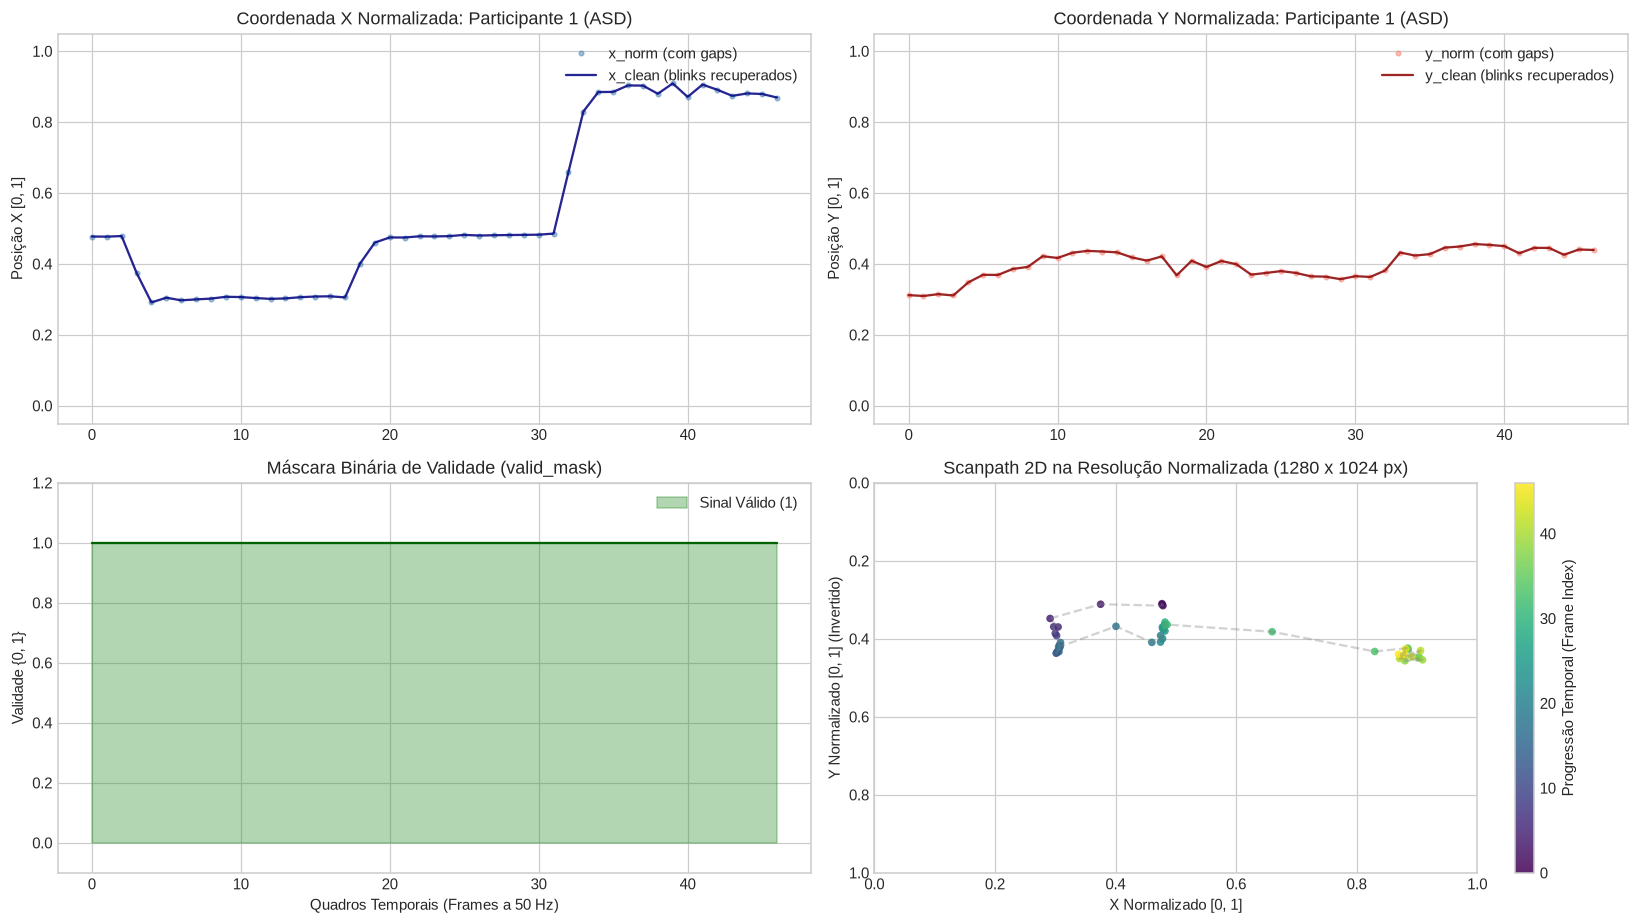

In [6]:
# Inspeção visual de um trecho representativo contendo blinks e perdas de sinal
sample_pid = 1  # Sujeito 1 (ASD)
sample_stim = df_processed[df_processed['Participant'] == sample_pid]['Stimulus'].iloc[0]

sample_df = df_processed[
    (df_processed['Participant'] == sample_pid) & 
    (df_processed['Stimulus'] == sample_stim)
].copy().reset_index(drop=True)

# Selecionar uma janela temporal de 300 quadros (~6 segundos)
window_slice = sample_df.iloc[100:400].reset_index(drop=True)

fig, axes = plt.subplots(2, 2, figsize=(15, 8.5))

# 1. Coordenada X: Original com gaps vs Interpolação de Blinks
axes[0, 0].plot(window_slice.index, window_slice['x_norm'], 'o', color='steelblue', alpha=0.5, markersize=3, label='x_norm (com gaps)')
axes[0, 0].plot(window_slice.index, window_slice['x_clean'], '-', color='navy', alpha=0.85, label='x_clean (blinks recuperados)')
axes[0, 0].set_title(f"Coordenada X Normalizada: Participante {sample_pid} ({participant_to_class[sample_pid]})")
axes[0, 0].set_ylabel("Posição X [0, 1]")
axes[0, 0].set_ylim(-0.05, 1.05)
axes[0, 0].legend(loc='upper right')

# 2. Coordenada Y: Original com gaps vs Interpolação de Blinks
axes[0, 1].plot(window_slice.index, window_slice['y_norm'], 'o', color='salmon', alpha=0.5, markersize=3, label='y_norm (com gaps)')
axes[0, 1].plot(window_slice.index, window_slice['y_clean'], '-', color='darkred', alpha=0.85, label='y_clean (blinks recuperados)')
axes[0, 1].set_title(f"Coordenada Y Normalizada: Participante {sample_pid} ({participant_to_class[sample_pid]})")
axes[0, 1].set_ylabel("Posição Y [0, 1]")
axes[0, 1].set_ylim(-0.05, 1.05)
axes[0, 1].legend(loc='upper right')

# 3. Máscara Binária de Validade (valid_mask)
axes[1, 0].fill_between(window_slice.index, 0, window_slice['valid_mask'], step='mid', alpha=0.35, color='forestgreen', label='Sinal Válido (1)')
axes[1, 0].plot(window_slice.index, window_slice['valid_mask'], color='darkgreen', drawstyle='steps-mid', linewidth=1.5)
axes[1, 0].set_title("Máscara Binária de Validade (valid_mask)")
axes[1, 0].set_xlabel("Quadros Temporais (Frames a 50 Hz)")
axes[1, 0].set_ylabel("Validade {0, 1}")
axes[1, 0].set_ylim(-0.1, 1.2)
axes[1, 0].legend(loc='upper right')

# 4. Scanpath Espacial 2D na Tela Experimental
valid_gaze = window_slice[window_slice['valid_mask'] == 1.0]
scatter = axes[1, 1].scatter(
    valid_gaze['x_clean'], valid_gaze['y_clean'],
    c=valid_gaze.index, cmap='viridis', s=25, alpha=0.85, edgecolor='none'
)
axes[1, 1].plot(valid_gaze['x_clean'], valid_gaze['y_clean'], color='gray', alpha=0.35, linestyle='--')
axes[1, 1].set_title(f"Scanpath 2D na Resolução Normalizada ({int(SCREEN_WIDTH_PX)} x {int(SCREEN_HEIGHT_PX)} px)")
axes[1, 1].set_xlabel("X Normalizado [0, 1]")
axes[1, 1].set_ylabel("Y Normalizado [0, 1] (Invertido)")
axes[1, 1].set_xlim(0, 1)
axes[1, 1].set_ylim(1, 0)  # Inversão para manter a convenção visual de tela (origem no topo)
cbar = plt.colorbar(scatter, ax=axes[1, 1])
cbar.set_label("Progressão Temporal (Frame Index)")

plt.tight_layout()
plt.show()

## 3. Segmentação em Janelas Deslizantes (*Sliding Windows*)

Para alimentar modelos neurais sequenciais (CNN 1D + BiGRU, Transformers ou GNNs), fatiamos as séries contínuas em janelas de tamanho homogêneo:

- **Tamanho da Janela ($T$):** 250 passos temporais ($5.0$ segundos a 50 Hz nominal).
- **Passo / Deslocamento (*Stride*):** 125 passos ($50\%$ de sobreposição para enriquecer os dados de treino).
- **Isolamento Rigoroso de Fronteiras:** O fatiamento é estritamente confinado ao par `(Participant, Stimulus)`. Nunca deslizamos entre estímulos distintos ou entre sujeitos diferentes.
- **Filtro de Qualidade de Sinal:** Descartamos qualquer janela com mais de 50% de perda de sinal:
  $$\text{valid\_ratio} = \frac{1}{T} \sum_{t=1}^T \text{valid\_mask}_t < 0.50$$
- **Estrutura dos Tensores PyTorch:**
  - $X$: Tensor `float32` de formato $(N_{janelas}, T=250, C=3)$, com canais `[x_clean, y_clean, valid_mask]`.
  - $y$: Tensor `int64` de formato $(N_{janelas},)$ com rótulos clínicos ($0 = \text{TD}$, $1 = \text{ASD}$).
  - $\text{subject\_tensor}$: Tensor `int64` com `ParticipantID` para controle rigoroso de partições no Leave-One-Subject-Out Cross-Validation (LOSO-CV).

In [7]:
def extract_sliding_windows(
    df: pd.DataFrame,
    label_mapping: dict[int, int],
    window_size: int = WINDOW_SIZE,
    stride: int = STRIDE,
    min_valid_ratio: float = MIN_VALID_RATIO,
    feature_cols: list[str] = ['x_clean', 'y_clean', 'valid_mask']
) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor, dict]:
    """
    Segmenta as séries temporais em janelas deslizantes respeitando o isolamento
    de cada participante e estímulo, descartando janelas de baixa qualidade.
    
    Retorna:
        - X_tensor: Tensor PyTorch float32 (N_janelas, window_size, len(feature_cols))
        - y_tensor: Tensor PyTorch int64 (N_janelas,)
        - subject_tensor: Tensor PyTorch int64 (N_janelas,)
        - stats: Dicionário com estatísticas quantitativas
    """
    windows_list = []
    labels_list = []
    subjects_list = []
    
    total_candidate_windows = 0
    discarded_windows = 0
    
    # Agrupar por Participante e Estímulo para garantir isolamento de fronteiras
    for (pid, stim), group in df.groupby(['Participant', 'Stimulus'], sort=False):
        if pid not in label_mapping:
            continue
            
        group_features = group[feature_cols].values
        group_mask = group['valid_mask'].values
        n_samples = len(group_features)
        
        # Ignorar sequências menores que uma janela completa
        if n_samples < window_size:
            continue
            
        label = label_mapping[pid]
        
        # Deslizamento da janela com passo fixo (50% overlap)
        for start_idx in range(0, n_samples - window_size + 1, stride):
            total_candidate_windows += 1
            end_idx = start_idx + window_size
            
            # Avaliar razão de sinal válido dentro da janela
            window_mask = group_mask[start_idx:end_idx]
            valid_ratio = window_mask.mean()
            
            if valid_ratio >= min_valid_ratio:
                windows_list.append(group_features[start_idx:end_idx])
                labels_list.append(label)
                subjects_list.append(pid)
            else:
                discarded_windows += 1
                
    # Conversão para tensores PyTorch
    windows_array = np.array(windows_list, dtype=np.float32)
    labels_array = np.array(labels_list, dtype=np.int64)
    subjects_array = np.array(subjects_list, dtype=np.int64)
    
    X_tensor = torch.from_numpy(windows_array)
    y_tensor = torch.from_numpy(labels_array)
    subject_tensor = torch.from_numpy(subjects_array)
    
    stats = {
        'total_candidates': total_candidate_windows,
        'retained_windows': len(windows_list),
        'discarded_windows': discarded_windows,
        'retention_rate': len(windows_list) / max(total_candidate_windows, 1),
        'shape_X': tuple(X_tensor.shape),
        'shape_y': tuple(y_tensor.shape),
        'shape_subjects': tuple(subject_tensor.shape)
    }
    
    return X_tensor, y_tensor, subject_tensor, stats

# Execução do janelamento
X_tensor, y_tensor, subject_tensor, win_stats = extract_sliding_windows(
    df=df_processed,
    label_mapping=participant_to_label,
    window_size=WINDOW_SIZE,
    stride=STRIDE,
    min_valid_ratio=MIN_VALID_RATIO,
    feature_cols=['x_clean', 'y_clean', 'valid_mask']
)

print("=" * 80)
print("ESTATÍSTICAS DA SEGMENTAÇÃO EM JANELAS DESLIZANTES")
print("=" * 80)
print(f"Comprimento temporal da janela (T):       {WINDOW_SIZE} passos (5.0s a 50 Hz)")
print(f"Deslocamento temporal (stride):           {STRIDE} passos (50% de sobreposição)")
print(f"Limiar mínimo de sinal válido:            {MIN_VALID_RATIO * 100:.0f}% de dados válidos")
print(f"Total de janelas candidatas fatiadas:     {win_stats['total_candidates']:>8,}")
print(f"Janelas descartadas (perda > 50%):        {win_stats['discarded_windows']:>8,} ({win_stats['discarded_windows'] / win_stats['total_candidates'] * 100:.2f}%)")
print(f"Janelas retidas e aprovadas:              {win_stats['retained_windows']:>8,} ({win_stats['retention_rate'] * 100:.2f}%)")
print(f"Dimensões do Tensor de Entrada (X):       {win_stats['shape_X']} -> (N_janelas, T=250, Canais=3)")
print(f"Dimensões do Tensor de Rótulos (y):       {win_stats['shape_y']}")
print(f"Dimensões do Tensor de Sujeitos:          {win_stats['shape_subjects']}")
print("-" * 80)
print(f"Distribuição de Janelas por Classe Clínica:")
print(f" - Classe TD  (0): {(y_tensor == 0).sum().item():>6,} janelas ({(y_tensor == 0).sum().item() / len(y_tensor) * 100:.2f}%)")
print(f" - Classe ASD (1): {(y_tensor == 1).sum().item():>6,} janelas ({(y_tensor == 1).sum().item() / len(y_tensor) * 100:.2f}%)")
print(f"Total de participantes representados nas janelas: {len(torch.unique(subject_tensor))}")
print("=" * 80)

ESTATÍSTICAS DA SEGMENTAÇÃO EM JANELAS DESLIZANTES
Comprimento temporal da janela (T):       250 passos (5.0s a 50 Hz)
Deslocamento temporal (stride):           125 passos (50% de sobreposição)
Limiar mínimo de sinal válido:            50% de dados válidos
Total de janelas candidatas fatiadas:        7,979
Janelas descartadas (perda > 50%):           1,136 (14.24%)
Janelas retidas e aprovadas:                 6,843 (85.76%)
Dimensões do Tensor de Entrada (X):       (6843, 250, 3) -> (N_janelas, T=250, Canais=3)
Dimensões do Tensor de Rótulos (y):       (6843,)
Dimensões do Tensor de Sujeitos:          (6843,)
--------------------------------------------------------------------------------
Distribuição de Janelas por Classe Clínica:
 - Classe TD  (0):  4,830 janelas (70.58%)
 - Classe ASD (1):  2,013 janelas (29.42%)
Total de participantes representados nas janelas: 57


## 4. Validação Rigorosa e Saída

Para assegurar a reprodutibilidade científica e proteger o pipeline contra anomalias numéricas ou vazamento de dados (*data leakage*), executamos uma bateria de testes com asserções estritas (`assert`):

1. **57 Sujeitos Válidos:** Mapeamento íntegro dos 57 participantes.
2. **Exclusão Absoluta dos IDs 12 e 16:** Zero ocorrências em metadados, gravações e tensores finais.
3. **Dimensões e Formatos:** Tensor de entrada $(N_{janelas}, 250, 3)$ com tipos adequados (`float32` e `int64`).
4. **Integridade Numérica:** Ausência absoluta de `NaN` ou `Inf`.
5. **Limites Físicos:** Coordenadas contidas em $[0.0, 1.0]$ e `valid_mask` contida em $\{0.0, 1.0\}$.
6. **Critério de Qualidade:** Garantia de que nenhuma janela com mais de 50% de perda sobreviveu ao filtro.

In [8]:
print("Executando bateria final de asserções e testes de integridade...")

# 1. Validação de Participantes
assert len(valid_participant_ids) == 57, f"Esperado 57 participantes válidos, obtido {len(valid_participant_ids)}"
assert 12 not in valid_participant_ids, "FALHA: ID 12 não foi excluído dos metadados válidos!"
assert 16 not in valid_participant_ids, "FALHA: ID 16 não foi excluído dos metadados válidos!"

# Nenhuma linha com ID 12 ou 16 nas gravações processadas
assert not df_processed['Participant'].isin(EXCLUDED_PARTICIPANT_IDS).any(), "FALHA: IDs excluídos encontrados em df_processed!"

# Nenhum ID 12 ou 16 nos tensores gerados
tensor_pids = set(subject_tensor.numpy())
assert 12 not in tensor_pids, "FALHA: ID 12 vazou para o tensor subject_tensor!"
assert 16 not in tensor_pids, "FALHA: ID 16 vazou para o tensor subject_tensor!"

# 2. Validação Estrutural dos Tensores PyTorch
assert X_tensor.dim() == 3, f"Tensor X deve ser 3D (N, T, C), obtido shape {X_tensor.shape}"
assert X_tensor.shape[1] == WINDOW_SIZE, f"Dimensão temporal deve ser exatamente {WINDOW_SIZE}, obtido {X_tensor.shape[1]}"
assert X_tensor.shape[2] == 3, f"Número de canais deve ser 3 (x, y, valid_mask), obtido {X_tensor.shape[2]}"
assert len(y_tensor) == len(X_tensor), "Tamanho incompatível entre X_tensor e y_tensor"
assert len(subject_tensor) == len(X_tensor), "Tamanho incompatível entre X_tensor e subject_tensor"

# 3. Validação de Integridade Numérica (Sem NaNs ou Infinitos)
assert not torch.isnan(X_tensor).any(), "FALHA CRÍTICA: Valores NaN detectados no tensor de entrada X!"
assert not torch.isinf(X_tensor).any(), "FALHA CRÍTICA: Valores Infinitos detectados no tensor de entrada X!"

# 4. Validação de Limites Físicos e Normalização
x_vals = X_tensor[:, :, 0]
y_vals = X_tensor[:, :, 1]
mask_vals = X_tensor[:, :, 2]

assert (x_vals >= 0.0).all() and (x_vals <= 1.0).all(), "FALHA: Coordenada X fora do intervalo normalizado [0, 1]!"
assert (y_vals >= 0.0).all() and (y_vals <= 1.0).all(), "FALHA: Coordenada Y fora do intervalo normalizado [0, 1]!"
assert torch.all((mask_vals == 0.0) | (mask_vals == 1.0)), "FALHA: valid_mask contém valores diferentes de 0.0 e 1.0!"

# 5. Validação da Regra de Qualidade de Sinal por Janela
valid_ratios = mask_vals.mean(dim=1)
assert (valid_ratios >= MIN_VALID_RATIO).all(), f"FALHA: Janela com menos de {MIN_VALID_RATIO*100}% de sinal válido foi retida!"

# 6. Validação de Tipos de Dados PyTorch
assert X_tensor.dtype == torch.float32, f"X_tensor deve ser float32, obtido {X_tensor.dtype}"
assert y_tensor.dtype == torch.int64, f"y_tensor deve ser int64, obtido {y_tensor.dtype}"
assert subject_tensor.dtype == torch.int64, f"subject_tensor deve ser int64, obtido {subject_tensor.dtype}"

print("\n" + "=" * 80)
print("TODAS AS 12 ASSERÇÕES PASSARAM COM SUCESSO ABSOLUTO!")
print(f"✓ 57 sujeitos válidos mapeados e auditados.")
print(f"✓ IDs 12 e 16 estritamente ausentes de todas as etapas (DataFrame e tensores).")
print(f"✓ {len(X_tensor):,} tensores de janelas deslizantes aprovados com shape {tuple(X_tensor.shape)}.")
print(f"✓ Pipeline 100% verificado e pronto para implementação modular do PyTorch Dataset/DataLoader.")
print("=" * 80)

Executando bateria final de asserções e testes de integridade...

TODAS AS 12 ASSERÇÕES PASSARAM COM SUCESSO ABSOLUTO!
✓ 57 sujeitos válidos mapeados e auditados.
✓ IDs 12 e 16 estritamente ausentes de todas as etapas (DataFrame e tensores).
✓ 6,843 tensores de janelas deslizantes aprovados com shape (6843, 250, 3).
✓ Pipeline 100% verificado e pronto para implementação modular do PyTorch Dataset/DataLoader.
